# 1. Enivornment Setup

In [1]:
!pip install econml doubleml

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import os
import re

from transformers import pipeline # sentiment analysis
from sklearn.model_selection import train_test_split # train / test split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier # for random forest models
from sklearn.preprocessing import StandardScaler
import doubleml as dml
from doubleml.datasets import fetch_bonus # need for double machine learning

# Control random seed
np.random.seed(1234)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 603.5/603.5 kB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.7/14.7 MB 85.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.9/151.9 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.3/230.3 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 3.6 MB/s eta 0:00:00
  Attempting uninstall: shap
    Found existing installation: shap 0.51.0
    Uninstalling shap-0.51.0:
      Successfully uninstalled shap-0.51.0


# 2. Load dataset

In [2]:
# load dataset
df = pd.read_parquet("reddit_dataset_final_politicaladded.parquet")

# display to confirm successful load
df.head()

,type,id,subreddit.id,subreddit.name,subreddit.nsfw,created_utc,permalink,domain,url,selftext,title,score,text_clean,political_affiliation,pol_left-wing,pol_neutral,pol_right-wing,rightwing_score,leftwing_score,neutral_score
590867,post,o22y4v,2l8qkv,niuz,False,1623951582,https://old.reddit.com/r/niuz/comments/o22y4v/...,self.niuz,None,"Ministrul Sănătății, Ioana Mihăilă, a declarat...",Testare Covid în farmacii. Ioana Mihăilă: Au f...,1,Testare Covid în farmacii. Ioana Mihăilă: Au f...,right-wing,False,False,True,0.376375,0.346851,0.276773
4186062,post,fqirvq,22gcg0,u_toronto_news,False,1585396350,https://old.reddit.com/r/u_toronto_news/commen...,globalnews.ca,https://globalnews.ca/video/6744565/toronto-co...,None,Toronto COVID-19 cases spike as city looks to ...,1,Toronto COVID-19 cases spike as city looks to ...,neutral,False,True,False,0.260800,0.241167,0.498033
2214654,post,jw08sh,22gcg0,u_toronto_news,False,1605643448,https://old.reddit.com/r/u_toronto_news/commen...,toronto.ctvnews.ca,https://toronto.ctvnews.ca/ontario-reports-mor...,None,"Ontario reports more than 1,200 new COVID-19 c...",1,"Ontario reports more than 1,200 new COVID-19 c...",neutral,False,True,False,0.331152,0.293318,0.375531
805769,post,n6vy3a,22gcg0,u_toronto_news,False,1620385532,https://old.reddit.com/r/u_toronto_news/commen...,cbc.ca,https://www.cbc.ca/news/health/covid-19-pandem...,None,Canada Post workers held retirement party amid...,1,Canada Post workers held retirement party amid...,neutral,False,True,False,0.328661,0.313806,0.357533
3249207,post,hk5ajj,2x4yx,coronavirus,False,1593723540,https://old.reddit.com/r/Coronavirus/comments/...,youtube.com,https://www.youtube.com/watch?v=3JkN8MR0Tys,None,Effect of Universal TB Vaccination and Other F...,4,Effect of Universal TB Vaccination and Other F...,neutral,False,True,False,0.200879,0.193009,0.606112


In [3]:
# define engagement variable as reddit score (upvotes minus downvotes)
df['engagement'] = df['score']
df['Y_log_engagement'] = np.log1p(df['engagement']) # take the log of engagement

df.head() # display updated dataset

,type,id,subreddit.id,subreddit.name,subreddit.nsfw,created_utc,permalink,domain,url,selftext,...,text_clean,political_affiliation,pol_left-wing,pol_neutral,pol_right-wing,rightwing_score,leftwing_score,neutral_score,engagement,Y_log_engagement
590867,post,o22y4v,2l8qkv,niuz,False,1623951582,https://old.reddit.com/r/niuz/comments/o22y4v/...,self.niuz,None,"Ministrul Sănătății, Ioana Mihăilă, a declarat...",...,Testare Covid în farmacii. Ioana Mihăilă: Au f...,right-wing,False,False,True,0.376375,0.346851,0.276773,1,0.693147
4186062,post,fqirvq,22gcg0,u_toronto_news,False,1585396350,https://old.reddit.com/r/u_toronto_news/commen...,globalnews.ca,https://globalnews.ca/video/6744565/toronto-co...,None,...,Toronto COVID-19 cases spike as city looks to ...,neutral,False,True,False,0.260800,0.241167,0.498033,1,0.693147
2214654,post,jw08sh,22gcg0,u_toronto_news,False,1605643448,https://old.reddit.com/r/u_toronto_news/commen...,toronto.ctvnews.ca,https://toronto.ctvnews.ca/ontario-reports-mor...,None,...,"Ontario reports more than 1,200 new COVID-19 c...",neutral,False,True,False,0.331152,0.293318,0.375531,1,0.693147
805769,post,n6vy3a,22gcg0,u_toronto_news,False,1620385532,https://old.reddit.com/r/u_toronto_news/commen...,cbc.ca,https://www.cbc.ca/news/health/covid-19-pandem...,None,...,Canada Post workers held retirement party amid...,neutral,False,True,False,0.328661,0.313806,0.357533,1,0.693147
3249207,post,hk5ajj,2x4yx,coronavirus,False,1593723540,https://old.reddit.com/r/Coronavirus/comments/...,youtube.com,https://www.youtube.com/watch?v=3JkN8MR0Tys,None,...,Effect of Universal TB Vaccination and Other F...,neutral,False,True,False,0.200879,0.193009,0.606112,4,1.609438


In [4]:
# Identify how many unique subreddits there are
num_subreddits = df['subreddit.name'].nunique()
print("Number of unique subreddits:", num_subreddits)

Number of unique subreddits: 100


In [5]:
# Identify how many subreddits have more than 20 posts in the randomized subsample
counts = df['subreddit.name'].value_counts()
print(f"Subreddits with more than 20 posts: {len(counts[counts>=20])}")

Subreddits with more than 20 posts: 100


# 3. Create Control Variables

In [6]:
# Length of Post
df['post_length'] = df['text_clean'].str.len()

# Urgency - measured as a score based on number of keywords, punctuation, and capital letters in a post
# Count of urgent words in a post
urgent_words = r'\b(breaking|urgent|now|alert|warning|attention|critical|must|stop)\b'
df['urgent_word_count'] = df['text_clean'].str.lower().apply(lambda x: len(re.findall(urgent_words,str(x))))

# Count number of ! and ? used
df['punctuation_count'] = df['text_clean'].str.count(r'[!?]')

# Count number of capital letters used
def count_caps(text):
  return sum(1 for char in str(text) if char.isupper())
df['capletter_count'] = df['text_clean'].apply(count_caps)

#Combine all three counts to get overall urgency
df['urgency'] = df['urgent_word_count'] + df['punctuation_count'] + df['capletter_count']

# Identify date variable
df['date'] = df['created_utc']

# Measure of sincerity, using idea of self-referential or group-referential language
sincere_words = r'\b(we|me|I|ours|us|my|mine|our)\b'
df['sincerity'] = df['text_clean'].str.lower().apply(lambda x: len(re.findall(sincere_words,str(x))))

df.head() # display updated dataset

,type,id,subreddit.id,subreddit.name,subreddit.nsfw,created_utc,permalink,domain,url,selftext,...,neutral_score,engagement,Y_log_engagement,post_length,urgent_word_count,punctuation_count,capletter_count,urgency,date,sincerity
590867,post,o22y4v,2l8qkv,niuz,False,1623951582,https://old.reddit.com/r/niuz/comments/o22y4v/...,self.niuz,None,"Ministrul Sănătății, Ioana Mihăilă, a declarat...",...,0.276773,1,0.693147,607,0,0,12,12,1623951582,0
4186062,post,fqirvq,22gcg0,u_toronto_news,False,1585396350,https://old.reddit.com/r/u_toronto_news/commen...,globalnews.ca,https://globalnews.ca/video/6744565/toronto-co...,None,...,0.498033,1,0.693147,102,0,0,6,6,1585396350,0
2214654,post,jw08sh,22gcg0,u_toronto_news,False,1605643448,https://old.reddit.com/r/u_toronto_news/commen...,toronto.ctvnews.ca,https://toronto.ctvnews.ca/ontario-reports-mor...,None,...,0.375531,1,0.693147,51,0,0,6,6,1605643448,0
805769,post,n6vy3a,22gcg0,u_toronto_news,False,1620385532,https://old.reddit.com/r/u_toronto_news/commen...,cbc.ca,https://www.cbc.ca/news/health/covid-19-pandem...,None,...,0.357533,1,0.693147,70,0,0,7,7,1620385532,0
3249207,post,hk5ajj,2x4yx,coronavirus,False,1593723540,https://old.reddit.com/r/Coronavirus/comments/...,youtube.com,https://www.youtube.com/watch?v=3JkN8MR0Tys,None,...,0.606112,4,1.609438,99,0,0,15,15,1593723540,0


In [7]:
# Still too many subreddits in sample for efficient computation. Thus, will proceed with using only top 100 subreddits
top_100 = df['subreddit.name'].value_counts().head(100).index # define top 100

df = df[df['subreddit.name'].isin(top_100)].copy() # save only top 100

# Check new sample size
print(f"New Total Rows: {len(df)}")
print(f"New Unique Subreddits: {df['subreddit.name'].nunique()}")

New Total Rows: 55821
New Unique Subreddits: 100


# 4. Create Political Variables

In [8]:
# Calculate a score for political salience. How much of the actual post is actually political?
df['political_salience'] = (1 - df['neutral_score']) *100 # multiplied by 100 to interpret as clear percent

# Calculate a score for political polarization.
# A score of 100 implies this post is extremely partisan
# A score of 0 implies the post is very balanced, more neutral leaning
numerator = df['rightwing_score'] - df['leftwing_score']
denominator = df['rightwing_score'] + df['leftwing_score']
df['partisan_score'] = np.abs(numerator / denominator) * 100 # multiplied by 100 to interpret as clear percent

df.head() # check updated dataset


,type,id,subreddit.id,subreddit.name,subreddit.nsfw,created_utc,permalink,domain,url,selftext,...,Y_log_engagement,post_length,urgent_word_count,punctuation_count,capletter_count,urgency,date,sincerity,political_salience,partisan_score
590867,post,o22y4v,2l8qkv,niuz,False,1623951582,https://old.reddit.com/r/niuz/comments/o22y4v/...,self.niuz,None,"Ministrul Sănătății, Ioana Mihăilă, a declarat...",...,0.693147,607,0,0,12,12,1623951582,0,72.322673,4.082243
4186062,post,fqirvq,22gcg0,u_toronto_news,False,1585396350,https://old.reddit.com/r/u_toronto_news/commen...,globalnews.ca,https://globalnews.ca/video/6744565/toronto-co...,None,...,0.693147,102,0,0,6,6,1585396350,0,50.196674,3.911312
2214654,post,jw08sh,22gcg0,u_toronto_news,False,1605643448,https://old.reddit.com/r/u_toronto_news/commen...,toronto.ctvnews.ca,https://toronto.ctvnews.ca/ontario-reports-mor...,None,...,0.693147,51,0,0,6,6,1605643448,0,62.446946,6.058576
805769,post,n6vy3a,22gcg0,u_toronto_news,False,1620385532,https://old.reddit.com/r/u_toronto_news/commen...,cbc.ca,https://www.cbc.ca/news/health/covid-19-pandem...,None,...,0.693147,70,0,0,7,7,1620385532,0,64.246729,2.312254
3249207,post,hk5ajj,2x4yx,coronavirus,False,1593723540,https://old.reddit.com/r/Coronavirus/comments/...,youtube.com,https://www.youtube.com/watch?v=3JkN8MR0Tys,None,...,1.609438,99,0,0,15,15,1593723540,0,39.388758,1.997919


# 5. Create controls for subreddits

In [9]:
# create dummies for each subreddit. Will use subreddit controls
subreddit_dummies = pd.get_dummies(df['subreddit.name'], prefix = 'sub', drop_first = True)
df = pd.concat([df, subreddit_dummies], axis = 1)

# 6. Causal Analysis - Double Machine Learning

In [10]:
# Define Outcome, Treatment, and Controls
outcome = 'Y_log_engagement'
treatment = 'partisan_score'

# Controls
base_controls = ['post_length', 'urgency', 'date', 'sincerity', 'pol_right-wing', 'pol_left-wing', 'political_salience']
subreddit_controls = [col for col in df.columns if col.startswith('sub_')]
features = subreddit_controls + base_controls

Y = df[outcome].to_numpy()
T = df[treatment].to_numpy()
X = df[features]

print("Outcome:", outcome)
print("Treatment:", treatment)
print("Number of features:", len(features))


Outcome: Y_log_engagement
Treatment: partisan_score
Number of features: 106


In [11]:
# ML Tuning
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [5, 8, 12],
    'min_samples_leaf': [1, 5]
}

# Construct DML Data object: bundling treatment, outcome, and controls
# Setting up for the model so that it knows exactly which columns correspond to treatment, effect, and controls
dml_data = dml.DoubleMLData(
    data=pd.concat([df[[outcome, treatment]], X], axis=1),
    y_col = outcome, # outcome
    d_cols = treatment, # treatment
    x_cols = features # controls, confounders
)

# Set up two models for DML
# 1. Outcome model: predict engagement using the controls
model_y = RandomForestRegressor(
    n_estimators=300, # using 300 trees to decide on the outcome
    max_depth=12, # prevents overfitting by trees getting too complex
    min_samples_leaf=5,
    random_state=1234,
    n_jobs=-1 # makes CPU process faster
)

# 2. Treatment model: predict partisan score using only the controls
model_t = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    random_state=1234,
    n_jobs=-1
)

# Since partisan score is a continuous treatment, use DoubleMLPLR (Partial Linear Regression)
dml_model = dml.DoubleMLPLR(
    dml_data,
    ml_g = model_y, # outcome model
    ml_m = model_t, # treatment model
    ml_l = model_y, # nuisance function for outcome given covariates
    n_folds = 5, # train on one part of data and test on another
    n_rep = 3
)


# Run tune
print("Starting hyperparameter tuning...")
dml_model.tune(
    param_grids = {'ml_l': param_grid, 'ml_m': param_grid}, # Pass param_grid directly to tune method
    search_mode = 'randomized_search',
    n_folds_tune = 2
)

print("Best Parameters for Nuisance Model (ml_l):")
print(dml_model.params['ml_l'])

print("Best Parameters for Treatment Model (ml_m):")
print(dml_model.params['ml_m'])

dml_model.fit()

/usr/local/lib/python3.12/dist-packages/doubleml/plm/plr.py:114: UserWarning: A learner ml_g has been provided for score = "partialling out" but will be ignored. "A learner ml_g is not required for estimation.
  warnings.warn(
/tmp/ipykernel_6474/294695421.py:49: FutureWarning: The 'tune' method using grid search or randomized search is maintained for backward compatibility. It will be removed in future versions. For more advanced hyperparameter optimization, consider using 'tune_ml_models' with Optuna, which offers Bayesian optimization and is generally more efficient. See the documentation for 'tune_ml_models' for usage examples.
  dml_model.tune(


Starting hyperparameter tuning...


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=100. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=100. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best Parameters for Nuisance Model (ml_l):
{'partisan_score': [[{'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}], [{'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}], [{'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}, {'n_estimators': 300, 'min_samples_leaf': 5, 'max_

In [12]:
# Print summary of the model
print("\n ================= DML: Average Treatment Effect =================\n")
print(dml_model.summary)


 ================= DML: Average Treatment Effect =================

                    coef   std err         t     P>|t|     2.5 %    97.5 %
partisan_score -0.001268  0.000494 -2.565448  0.010304 -0.002237 -0.000299


In [13]:
# Output to LaTeX for paper
print(dml_model.summary.to_latex(float_format="%.4f"))

\begin{tabular}{lrrrrrr}
\toprule
 & coef & std err & t & P>|t| & 2.5 % & 97.5 % \\
\midrule
partisan_score & -0.0013 & 0.0005 & -2.5654 & 0.0103 & -0.0022 & -0.0003 \\
\bottomrule
\end{tabular}



In [14]:
# Compare with OLS
import statsmodels.api as sm

# Convert boolean columns to integers (0 or 1) for statsmodels
cols_to_convert = [col for col in features if col in df.columns and df[col].dtype == bool]
for col in cols_to_convert:
    df[col] = df[col].astype(int)

# combine all
ols_data = pd.concat([df[treatment], df[features]], axis = 1)

# add constant
ols_data = sm.add_constant(ols_data)

# run the OLS model
ols_model = sm.OLS(df[outcome], ols_data).fit()

# extract to make a table for paper
comparison_df = pd.DataFrame({
    "Model": ["OLS", "DML"],
    "Coefficient": [ols_model.params[treatment], dml_model.summary.loc[treatment, 'coef']],
    "Std. Err.": [ols_model.bse[treatment], dml_model.summary.loc[treatment, 'std err']],
    "t-stat": [ols_model.tvalues[treatment], dml_model.summary.loc[treatment, 't']]
})

#Output to LaTeX
print("\n================= Model Comparison: OLS vs DML =================\n")
print(comparison_df.to_latex(index = False, float_format = "%.4f"))


================= Model Comparison: OLS vs DML =================

\begin{tabular}{lrrr}
\toprule
Model & Coefficient & Std. Err. & t-stat \\
\midrule
OLS & -0.0003 & 0.0003 & -0.9627 \\
DML & -0.0013 & 0.0005 & -2.5654 \\
\bottomrule
\end{tabular}



#7. Causal Analysis - Causal Forest

In [15]:
from econml.dml import CausalForestDML

# Define heterogeneity characteristics that we are interested in looking at
X_cols = ["pol_left-wing", "pol_right-wing", "urgency", "political_salience", "sincerity"]
X = df[X_cols]

# Define variables that will remain as controls: post-length and subreddits
W_cols = [c for c in features if c not in X_cols]
W = df[W_cols]

# print heterogeneity features and count the number of controls
print("\nHeterogeneity features X:", X_cols)
print("Additional controls W:", len(W_cols))


Heterogeneity features X: ['pol_left-wing', 'pol_right-wing', 'urgency', 'political_salience', 'sincerity']
Additional controls W: 101


In [16]:
# Initialize the Causal Forest
cf = CausalForestDML(
    model_y=RandomForestRegressor(
        n_estimators=300, # 300 trees
        max_depth=12,
        min_samples_leaf=5,
        random_state=1234,
        n_jobs=-1
    ),
    model_t=RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        random_state=1234,
        n_jobs=-1
    ),
    n_estimators=500, # 500 trees
    min_samples_leaf=10,
    max_depth=None,
    discrete_treatment=False, # continuous treatment
    honest=True,
    cv=3, # model divided into 3 equal portions
    random_state=1234,
    n_jobs=-1
)

cf.fit(
    Y=Y,
    T=T,
    X=X.to_numpy(),
    W=W.to_numpy()
)

In [17]:
# Estimate Individual Treatment Effects
tau_hat = cf.effect(X.to_numpy())
tau_lb, tau_ub = cf.effect_interval(X.to_numpy(), alpha=0.05)

results = X.copy()
results["tau_hat"] = tau_hat # effect for each category
results["tau_lb"] = tau_lb # lower bound
results["tau_ub"] = tau_ub # upper bound

# print results
print("\n================ Causal Forest: Heterogeneous Effects ================\n")
print(results.head())

print("\nAverage estimated CATE from causal forest:", results["tau_hat"].mean())


================ Causal Forest: Heterogeneous Effects ================

         pol_left-wing  pol_right-wing  urgency  political_salience  \
590867               0               1       12           72.322673   
4186062              0               0        6           50.196674   
2214654              0               0        6           62.446946   
805769               0               0        7           64.246729   
3249207              0               0       15           39.388758   

         sincerity   tau_hat    tau_lb    tau_ub  
590867           0 -0.002463 -0.009508  0.004581  
4186062          0 -0.018072 -0.039485  0.003341  
2214654          0 -0.011985 -0.026632  0.002663  
805769           0 -0.010349 -0.026561  0.005864  
3249207          0 -0.006724 -0.015193  0.001745  

Average estimated CATE from causal forest: -0.0008789693168690864


In [18]:
# summarize model estimated heterogeneity
# pair features w/ predictions
CF_results = X.copy()
CF_results["tau_hat"] = cf.effect(X.values)

print("\n================ Subgroup Analysis ================\n")

subgroup_rows =[] # stores results for output to LaTeX table

for col in X_cols: # iterate for each variable that I am interested in looking at

    temp_df = results[[col, 'tau_hat']].copy()

    # discrete variables
    if results[col].nunique() <= 2:
        grp = temp_df.groupby(col)["tau_hat"].agg(["mean", "std", "count"]).sort_index() # relevant results
        labels2 = ["No", "Yes"] if grp.index[0] in [0, False] else grp.index

        for i, label in enumerate(labels2):
            mean = grp.iloc[i]["mean"] # mean
            std = grp.iloc[i]["std"] # standard deviation
            count = int(grp.iloc[i]["count"]) # number of observations

            tstat = (mean - 0) / (std / np.sqrt(count)) # t-stat to show if effect is significant

            # add results to array
            subgroup_rows.append({
                  "Feature": col,
                  "Group": label,
                  "Mean": mean,
                  "Std Dev": std,
                  "Observations": count,
                  "T-stat": tstat
              })

    # continuous variables
    else:
      # use median split to compare low vs high
      median_val = temp_df[col].median()
      temp_df['is_high_val'] = temp_df[col] > median_val
      grp = temp_df.groupby('is_high_val')["tau_hat"].agg(["mean", "std", "count"]) # relevant results

      labels3 = [f"Low (≤{median_val})", f"High (>{median_val})"]
      for i, label in enumerate(labels3):

        mean = grp.iloc[i]["mean"] # mean
        std = grp.iloc[i]["std"] # standard deviation
        count = int(grp.iloc[i]["count"]) # no. of observations

        tstat = (mean - 0) / (std / np.sqrt(count)) # t-stat to show if effect is significant

        # add results to array
        subgroup_rows.append({
              "Feature": col,
              "Group": label,
              "Mean": mean,
              "Std Dev": std,
              "Observations": count,
              "T-stat": tstat
          })

      # convert to data frame
      latex_df = pd.DataFrame(subgroup_rows)
      # export to latex
      print(latex_df.to_latex(
          index = False,
          caption="Conditional Average Treatment Effect (CATE) by Subgroup", # caption for table
          label = "tab:subgroup_analysis", # label for table
          float_format = "%.4f", # 4 decimal places
          column_format="lllccc", # format columns for table
          escape = False,
          bold_rows = True
          ))


================ Subgroup Analysis ================

\begin{table}
\caption{Conditional Average Treatment Effect (CATE) by Subgroup}
\label{tab:subgroup_analysis}
\begin{tabular}{lllccc}
\toprule
Feature & Group & Mean & Std Dev & Observations & T-stat \\
\midrule
pol_left-wing & No & -0.0008 & 0.0106 & 52341 & -17.3664 \\
pol_left-wing & Yes & -0.0020 & 0.0057 & 3480 & -20.4294 \\
pol_right-wing & No & -0.0008 & 0.0108 & 48781 & -15.5310 \\
pol_right-wing & Yes & -0.0017 & 0.0063 & 7040 & -22.3566 \\
urgency & Low (≤7.0) & 0.0002 & 0.0120 & 28072 & 2.3077 \\
urgency & High (>7.0) & -0.0019 & 0.0083 & 27749 & -38.8803 \\
\bottomrule
\end{tabular}
\end{table}

\begin{table}
\caption{Conditional Average Treatment Effect (CATE) by Subgroup}
\label{tab:subgroup_analysis}
\begin{tabular}{lllccc}
\toprule
Feature & Group & Mean & Std Dev & Observations & T-stat \\
\midrule
pol_left-wing & No & -0.0008 & 0.0106 & 52341 & -17.3664 \\
pol_left-wing & Yes & -0.0020 & 0.0057 & 3480 & -20.4294 \\

Variable Importance


Heterogeneity feature importances:
urgency               0.467279
political_salience    0.353587
sincerity             0.165782
pol_right-wing        0.008195
pol_left-wing         0.005156
dtype: float64


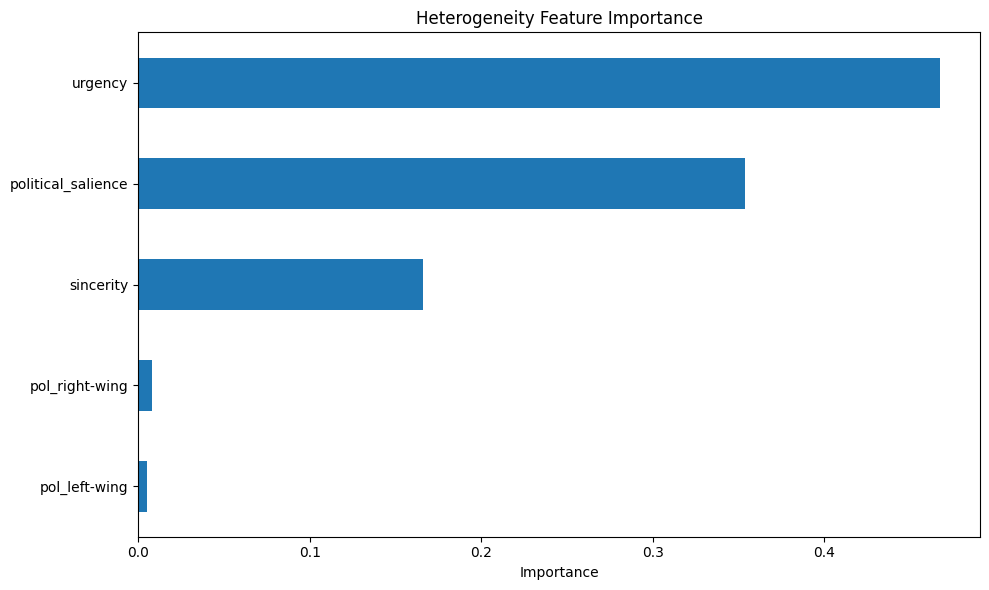

In [19]:
# print variable importance
fi = pd.Series(cf.feature_importances_, index = X.columns).sort_values(ascending = False)
print("\nHeterogeneity feature importances:")
print(fi)

# Graph feature importance
plt.figure(figsize = (10, 6))
fi.sort_values().plot(kind="barh")
plt.title("Heterogeneity Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# Save plot as an image
plt.savefig('feature_importance.png', dpi = 300, bbox_inches = 'tight')
plt.close()


In [20]:
# Rank units by estimated treatment effect

top = results.sort_values("tau_hat", ascending = False).head(10) # top 10
bottom = results.sort_values("tau_hat", ascending = True).head(10) # bottom 10

print("\nTop 10 Units by estimated treatment effect:")
print(top)

print("\nBottom 10 Units by estimated treatment effect:")
print(bottom)


Top 10 Units by estimated treatment effect:
         pol_left-wing  pol_right-wing  urgency  political_salience  \
1621780              0               0        6           40.510321   
1625961              0               0        6           40.510321   
1618287              0               0        6           40.510321   
1626099              0               0        6           40.510321   
1628649              0               0        6           40.510321   
1627920              0               0        6           40.510321   
2991058              0               0        6           40.509254   
3690303              0               0        6           40.500003   
3696967              0               0        6           40.500003   
1447220              0               0        6           40.540969   

         sincerity   tau_hat    tau_lb    tau_ub  
1621780          0  0.068215 -0.039266  0.175697  
1625961          0  0.068215 -0.039266  0.175697  
1618287          0  

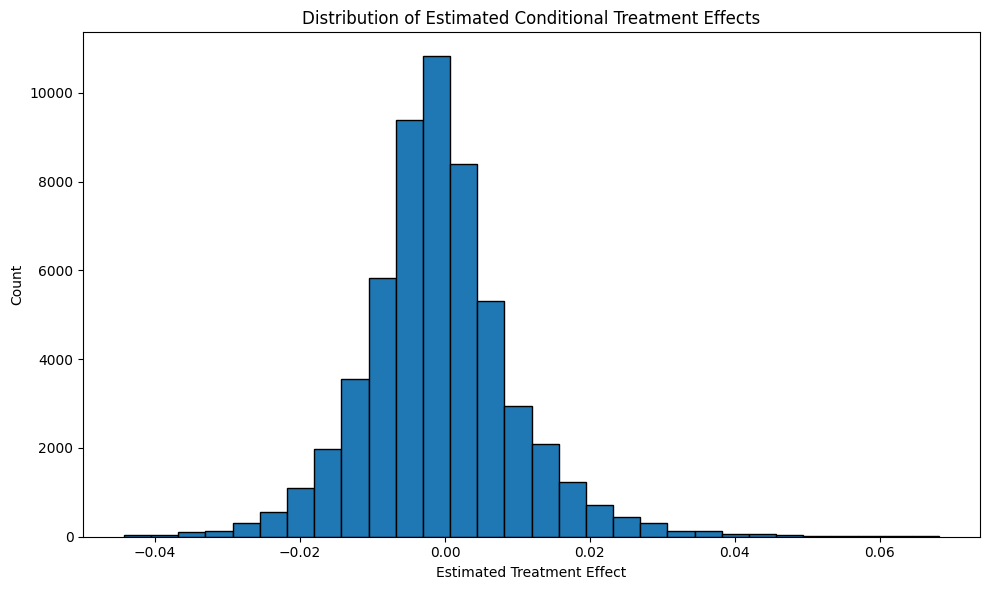

In [21]:
# plot of distribution of estimated TE
plt.figure(figsize = (10, 6))
plt.hist(results["tau_hat"], bins = 30, edgecolor = "black")
plt.title("Distribution of Estimated Conditional Treatment Effects")
plt.xlabel("Estimated Treatment Effect")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Save plot as an image
plt.savefig('TE_histogram.png', dpi = 300, bbox_inches = 'tight')
plt.close()

# 8. Descriptive Stats

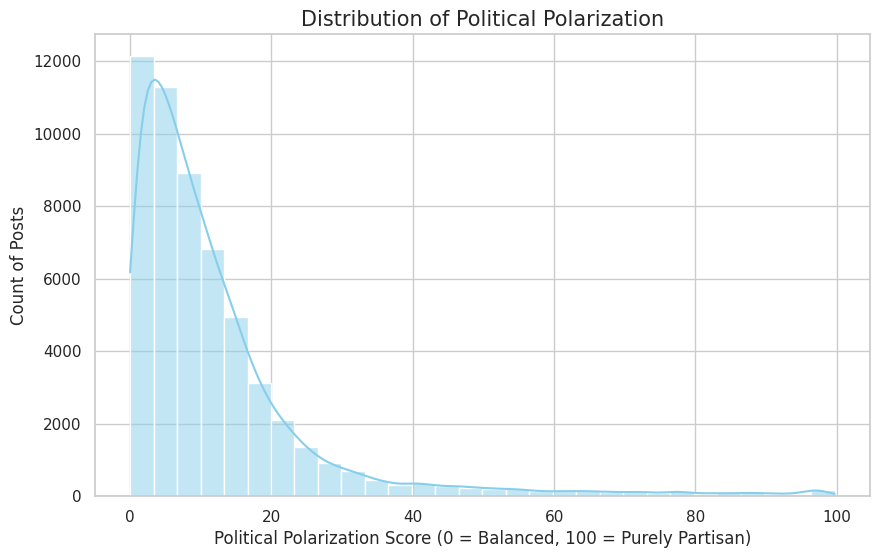

In [22]:
import seaborn as sns

# set theme
sns.set_theme(style = "whitegrid")

# 1. Histogram for Polarization
plt.figure(figsize=(10,6))
sns.histplot(df['partisan_score'], bins = 30, kde = True, color = 'skyblue')
plt.title('Distribution of Political Polarization', fontsize = 15)
plt.xlabel('Political Polarization Score (0 = Balanced, 100 = Purely Partisan)', fontsize = 12)
plt.ylabel('Count of Posts', fontsize = 12)
plt.show()

# Save plot as an image
plt.savefig('polarization_histogram.png', dpi = 300, bbox_inches = 'tight')
plt.close()

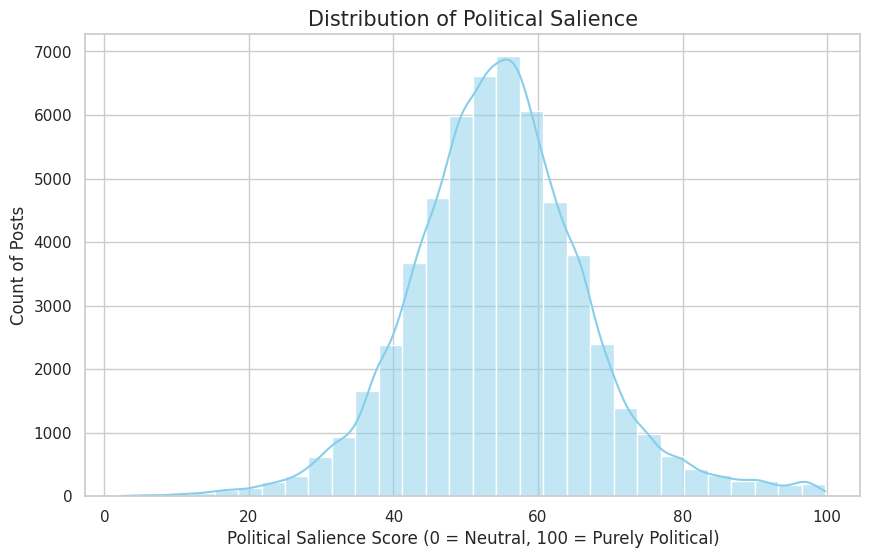

In [23]:
# 2. Histogram for Political Salience
plt.figure(figsize=(10,6))
sns.histplot(df['political_salience'], bins = 30, kde = True, color = 'skyblue')
plt.title('Distribution of Political Salience', fontsize = 15)
plt.xlabel('Political Salience Score (0 = Neutral, 100 = Purely Political)', fontsize = 12)
plt.ylabel('Count of Posts', fontsize = 12)
plt.show()

# Save plot as an image
plt.savefig('salience_histogram.png', dpi = 300, bbox_inches = 'tight')
plt.close()

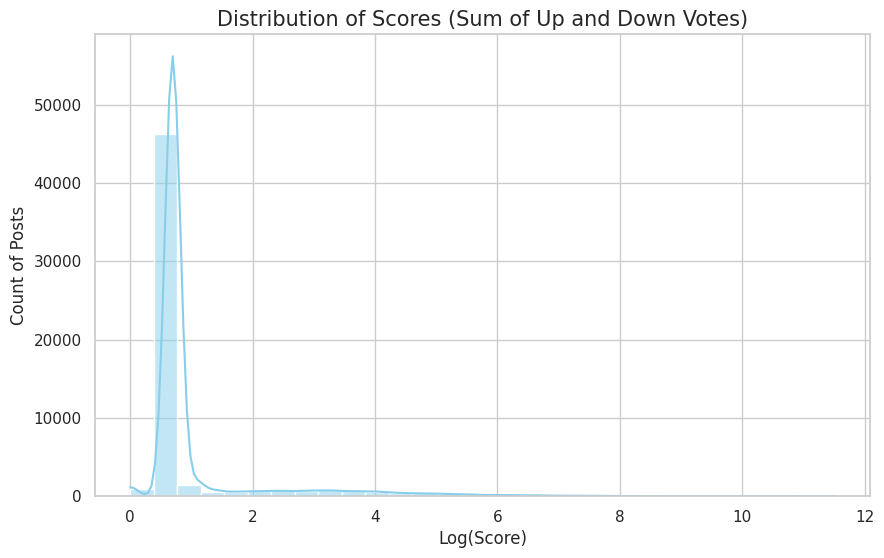

In [24]:
# 3. Histogram for Engagement
plt.figure(figsize=(10,6))
sns.histplot(df['Y_log_engagement'], bins = 30, kde = True, color = 'skyblue')
plt.title('Distribution of Scores (Sum of Up and Down Votes)', fontsize = 15)
plt.xlabel('Log(Score)', fontsize = 12)
plt.ylabel('Count of Posts', fontsize = 12)
plt.show()

# Save plot as an image
plt.savefig('engagement_histogram.png', dpi = 300, bbox_inches = 'tight')
plt.close()

/tmp/ipykernel_6474/4134447358.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = aff_count.index, y = aff_count.values,


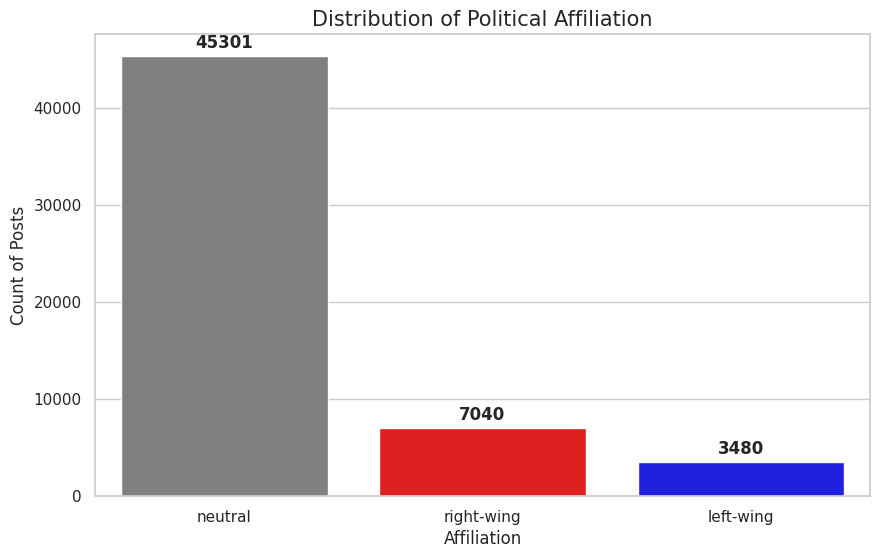

In [25]:
# chart for left wing, right wing, neutral
aff_count = df['political_affiliation'].value_counts() # calculate the distribution

#create bar plot
plt.figure(figsize=(10,6))
sns.barplot(x = aff_count.index, y = aff_count.values,
            palette = {'left-wing': 'blue', 'neutral': 'gray', 'right-wing':'red'})

# add counts to bar graph
for i, v in enumerate(aff_count.values):
    plt.text(i, v + (max(aff_count.values)* 0.01), str(v), ha='center', va='bottom', fontweight = 'bold')

plt.title('Distribution of Political Affiliation', fontsize = 15)
plt.xlabel('Affiliation', fontsize = 12)
plt.ylabel('Count of Posts', fontsize = 12)
plt.show()

plt.savefig('affiliation.png', dpi = 300, bbox_inches = 'tight')
plt.close()


In [26]:
# Table of Descriptive Stats for all continuous variables
# array of the continuous variables
continuous_vars = ['post_length', 'urgency', 'sincerity', 'political_salience', 'partisan_score','engagement', "Y_log_engagement"]

# calculate descriptive stats
d_stats = df[continuous_vars].describe().transpose()
d_stats = d_stats[['count', 'mean', 'std', 'min', 'max']]

# output to LaTeX
latex_code = d_stats.to_latex(
    index = True,
    column_format = "lccccc", # column centering
    float_format = "%.2f" # 2 decimal places
)

print(latex_code)


\begin{tabular}{lccccc}
\toprule
 & count & mean & std & min & max \\
\midrule
post_length & 55821.00 & 134.11 & 416.95 & 6.00 & 29895.00 \\
urgency & 55821.00 & 10.04 & 17.60 & 0.00 & 1277.00 \\
sincerity & 55821.00 & 0.13 & 0.88 & 0.00 & 58.00 \\
political_salience & 55821.00 & 54.71 & 12.18 & 2.24 & 99.74 \\
partisan_score & 55821.00 & 12.28 & 14.43 & 0.00 & 99.70 \\
engagement & 55821.00 & 54.64 & 1204.91 & 0.00 & 99881.00 \\
Y_log_engagement & 55821.00 & 1.05 & 1.12 & 0.00 & 11.51 \\
\bottomrule
\end{tabular}

